### General imports

In [18]:
import numpy as np
import pandas as pd

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt


### Read data and add necessary features

In [9]:
data_train = pd.read_csv('data/case1/train1.csv')
data_test = pd.read_csv('data/case1/test1.csv')

data_train['speed_krpm'] = data_train.speed_rpm / 1000
data_train['delta_p'] = data_train.outlet_pressure_bar - data_train.inlet_pressure_bar

data_test['speed_krpm'] = data_test.speed_rpm / 1000
data_test['delta_p'] = data_test.outlet_pressure_bar - data_test.inlet_pressure_bar


data_train.head()
print(len(data_train))
print(len(data_test))
print(data_train.columns)
print(data_train.describe())


X_train = data_train[['speed_krpm','power_w','delta_p']]
y_train = data_train['flow_m3_h']




X_test = data_test[['speed_krpm','power_w','delta_p']]
y_test = data_test['flow_m3_h']



480
120
Index(['pump_id', 'elapsed_s', 'operating_state', 'speed_rpm', 'power_w',
       'inlet_pressure_bar', 'outlet_pressure_bar', 'flow_m3_h', 'speed_krpm',
       'delta_p'],
      dtype='object')
        elapsed_s    speed_rpm      power_w  inlet_pressure_bar  \
count   480.00000   480.000000   480.000000          480.000000   
mean   3004.50000  3167.585295   703.518374            1.754341   
std    1733.83377   993.327115   553.346321            0.437575   
min      14.50000  1494.159036    63.185204            0.993489   
25%    1509.50000  2358.834776   227.256230            1.338162   
50%    3004.50000  3221.081886   551.359686            1.791819   
75%    4499.50000  4073.168668  1042.022701            2.112261   
max    5994.50000  4813.199117  2201.655665            2.514032   

       outlet_pressure_bar   flow_m3_h  speed_krpm     delta_p  
count           480.000000  480.000000  480.000000  480.000000  
mean              2.421464   18.792311    3.167585    0.667123  

### _Exploratory data analysis done before, data is clean already_

# SVM

In [17]:

# Create pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# Define hyperparameter grid
param_grid = [

    {
        'svr__kernel': ['rbf'],
        'svr__C': [0.1, 1, 10, 100],
        'svr__epsilon': [0.01, 0.1, 0.5, 1],
        'svr__gamma': ['scale', 'auto', 0.01, 0.1, 1]
    },
    {
        'svr__kernel': ['poly'],
        'svr__C': [0.1, 1, 10, 100],
        'svr__epsilon': [0.01, 0.1, 0.5],
        'svr__gamma': ['scale', 'auto'],
        'svr__degree': [2, 3]
    }
]

# Grid Search with Cross Validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    verbose = 3
)

# Train model
grid_search.fit(X_train, y_train)

# Best model
SVR_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)



Fitting 5 folds for each of 128 candidates, totalling 640 fits
[CV 1/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=scale, svr__kernel=rbf;, score=-12.860 total time=   0.0s
[CV 2/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=scale, svr__kernel=rbf;, score=-12.121 total time=   0.0s
[CV 3/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=scale, svr__kernel=rbf;, score=-10.068 total time=   0.0s
[CV 4/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=scale, svr__kernel=rbf;, score=-10.775 total time=   0.0s
[CV 5/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=scale, svr__kernel=rbf;, score=-9.801 total time=   0.0s
[CV 1/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=auto, svr__kernel=rbf;, score=-12.860 total time=   0.0s
[CV 2/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=auto, svr__kernel=rbf;, score=-12.121 total time=   0.0s
[CV 3/5] END svr__C=0.1, svr__epsilon=0.01, svr__gamma=auto, svr__kernel=rbf;, score=-10.068 total time=   0.0s
[CV 4/5] END svr__C=0.1, svr__epsilon

### Test data

In [16]:


# Predictions
y_pred = SVR_model.predict(X_test)

# Evaluate model
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

RMSE: 0.6929675670725327
R2 Score: 0.9967052232248663


### Plots

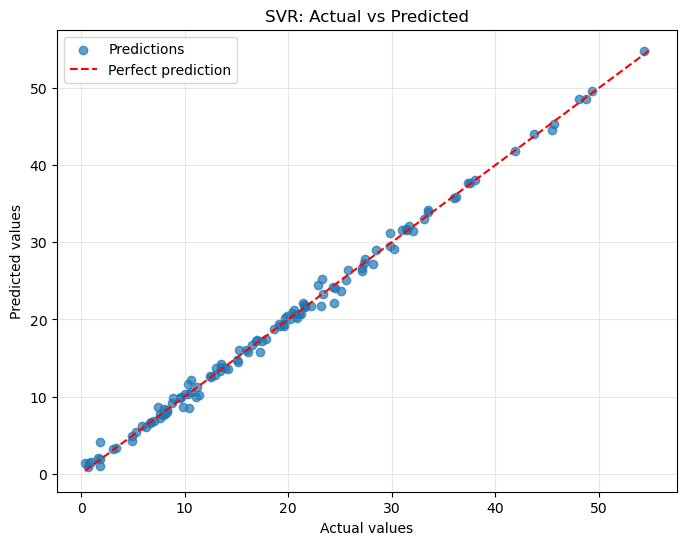

In [19]:
# Plot
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7, label='Predictions')

# Perfect prediction line
min_val = min(np.min(y_test), np.min(y_pred))
max_val = max(np.max(y_test), np.max(y_pred))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect prediction'
)

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('SVR: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.3)
plt.show()